# Lab 6: Data Transformation & Feature Engineering

In this lab, we will learn **when** and **how** to apply different transformation techniques to a dataset. 

We will work with an **Employee Attrition & Performance** dataset that contains a mix of numerical, categorical, and ordinal features, each requiring a specific treatment.

**Key Topics:**
1. **Feature Scaling:** Standardization vs. Normalization vs. Robust Scaling.
2. **Feature Encoding:** One-Hot, Label, Target, Frequency, and **Binary Encoding**.
3. **Discretization:** Binning continuous variables.
4. **Feature Interactions:** Creating new features from existing ones.
5. **Feature Selection:** Identifying the most important features.
6. **Documentation:** Keeping track of your work.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
from datetime import datetime

# Install category_encoders if not already installed
try:
    import category_encoders as ce
except ImportError:
    %pip install category_encoders
    import category_encoders as ce

# --- 1. Load Dataset from SQLite ---
conn = sqlite3.connect('lab6.db')
data = pd.read_sql('SELECT * FROM employees', conn)
conn.close()

# Drop EmployeeID - it's just an identifier, not a feature
data = data.drop('EmployeeID', axis=1)

print("Dataset Shape:", data.shape)
data.head()


Dataset Shape: (1000, 9)


,Age,Income,Performance_Score,Department,Education_Level,Job_Role,Years_Experience,Monthly_Rate,Attrition
0,38,195825.283784,1.9,R&D,High School,Executive Assistant,11.5,16186.264829,1
1,33,177612.204321,1.1,Sales,High School,Research Director,2.9,14495.752472,0
2,40,402946.028676,1.4,Sales,Bachelor,Manager,3.5,33510.284024,0
3,47,456448.734878,2.4,R&D,Bachelor,IT Support,18.3,38217.681406,1
4,33,158023.936684,4.2,R&D,High School,Legal Counsel,8.9,12980.701968,1


## 1.1 Transformation Logging
We will use a `DataTransformationLog` class to track all our transformations systematically.

In [3]:
class DataTransformationLog:
    """
    A comprehensive data cleaning logger that tracks all transformations
    """
    
    def __init__(self, dataset_name, analyst_name):
        self.dataset_name = dataset_name
        self.analyst_name = analyst_name
        self.start_time = datetime.now()
        self.log_entries = []
        self.summary_stats = {
            'initial': {},
            'final': {}
        }
        
    def log_action(self, category, action, details, rows_affected=None, 
                   columns_affected=None, before_value=None, after_value=None):
        """
        Log a data cleaning action
        """
        entry = {
            'timestamp': datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
            'category': category,
            'action': action,
            'details': details,
            'rows_affected': rows_affected,
            'columns_affected': columns_affected if columns_affected else [],
            'before_value': str(before_value) if before_value is not None else None,
            'after_value': str(after_value) if after_value is not None else None
        }
        self.log_entries.append(entry)
        
    def to_dataframe(self):
        """Convert log to DataFrame"""
        return pd.DataFrame(self.log_entries)

# Initialize Log
log = DataTransformationLog(dataset_name="Employee_Attrition", analyst_name="Instructor")
print("Log Initialized.")


Log Initialized.


## 2. Exploratory Data Analysis (EDA) for Transformation
Before applying any transformation, we must understand the data's distribution and types.

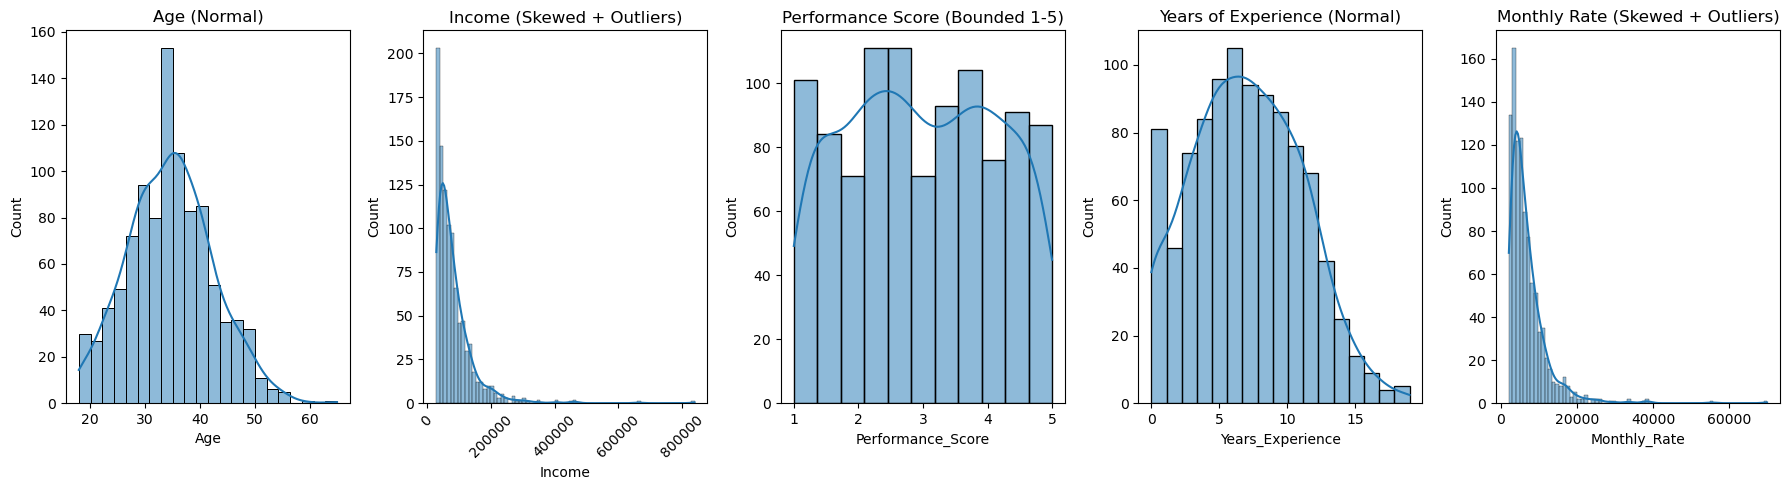

Department          3
Education_Level     4
Job_Role           20
dtype: int64


In [4]:
# Check distributions of numerical features
fig, axes = plt.subplots(1, 5, figsize=(18, 5))

sns.histplot(data['Age'], kde=True, ax=axes[0]).set_title('Age (Normal)')

# Rotate x-axis labels for Income to handle large numbers
sns.histplot(data['Income'], kde=True, ax=axes[1]).set_title('Income (Skewed + Outliers)')
axes[1].tick_params(axis='x', rotation=45)

sns.histplot(data['Performance_Score'], kde=True, ax=axes[2]).set_title('Performance Score (Bounded 1-5)')

sns.histplot(data['Years_Experience'], kde=True, ax=axes[3]).set_title('Years of Experience (Normal)')

sns.histplot(data['Monthly_Rate'], kde=True, ax=axes[4]).set_title('Monthly Rate (Skewed + Outliers)')


plt.tight_layout()
plt.show()

# Check cardinality of categorical features
print(data[['Department', 'Education_Level', 'Job_Role']].nunique())


## 3. Feature Scaling
* When you have different orders of magnitude within your data, you must normalize them.
* Machine learning algorithms that use distance metrics, such as k-nearest neighbors, support vector machines, and neural networks, are particularly sensitive to the scale of input features.

We choose the scaling technique based on the feature's distribution.




### 3.1 Standardization (Z-Score)
- **Formula:** $$z = \frac{x - \mu}{\sigma}$$
- **Assumption:** Can be applied to any numerical distribution, regardless of its shape, provided the mean and standard deviation can be calculated. 
- **Effect:** Centers data around 0 with a standard deviation of 1.
- **Use Case:** `Age` (looks normally distributed).

Age Mean: -0.00, Std: 1.00
Min: -2.15, Max: 3.90


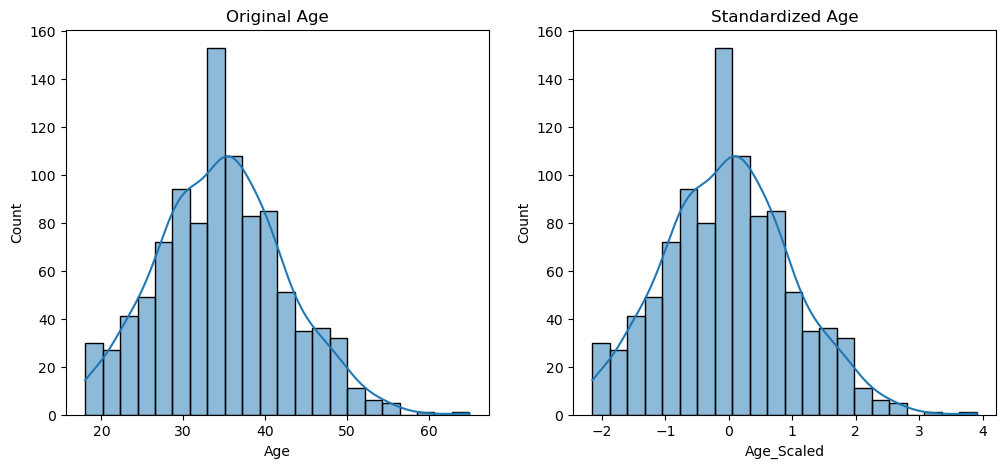

In [5]:
from sklearn.preprocessing import StandardScaler

# fit_trasform vs transform
scaler_std = StandardScaler()
data['Age_Scaled'] = scaler_std.fit_transform(data[['Age']])

# Log the action
log.log_action(
    category='Scaling',
    action='StandardScaler',
    details='Applied Z-Score standardization to Age (Normal distribution).',
    columns_affected=['Age']
)

print(f"Age Mean: {data['Age_Scaled'].mean():.2f}, Std: {data['Age_Scaled'].std():.2f}")
print(f"Min: {data['Age_Scaled'].min():.2f}, Max: {data['Age_Scaled'].max():.2f}")

# Plot to show it's not bounded between -1 and 1
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(data['Age'], kde=True).set_title("Original Age")
plt.subplot(1, 2, 2)
sns.histplot(data['Age_Scaled'], kde=True).set_title("Standardized Age")
plt.show()

# Drop original Age to avoid multicollinearity later
data = data.drop('Age', axis=1)


### 3.2 Min-Max Normalization
- **Formula:** $$x_{norm} = \frac{x - x_{min}}{x_{max} - x_{min}}$$
- **Effect:** Scales data to a fixed range, usually [0, 1].
- **Use Case:** `Performance_Score` (bounded data).

Performance Range: [0.00, 1.00]


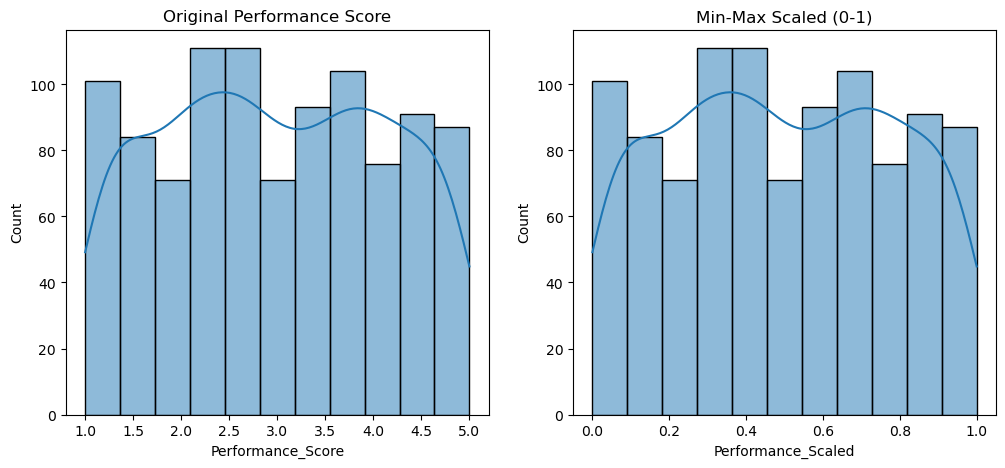

In [6]:
from sklearn.preprocessing import MinMaxScaler

scaler_minmax = MinMaxScaler()
data['Performance_Scaled'] = scaler_minmax.fit_transform(data[['Performance_Score']])

# Log the action
log.log_action(
    category='Scaling',
    action='MinMaxScaler',
    details='Scaled Performance_Score to [0, 1] range.',
    columns_affected=['Performance_Score']
)

print(f"Performance Range: [{data['Performance_Scaled'].min():.2f}, {data['Performance_Scaled'].max():.2f}]")

# Compare Before and After
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data['Performance_Score'], kde=True, ax=axes[0]).set_title('Original Performance Score')
sns.histplot(data['Performance_Scaled'], kde=True, ax=axes[1]).set_title('Min-Max Scaled (0-1)')
plt.show()

# Drop original Performance_Score
data = data.drop('Performance_Score', axis=1)


### 3.3 Robust Scaling
- **Formula:** $$x_{robust} = \frac{x - \text{median}}{\text{IQR}}$$
- **Effect:** Scales data similarly to standardization but is robust to outliers.
- **Use Case:** `Income` and `Monthly_rate` (highly skewed with extreme outliers).

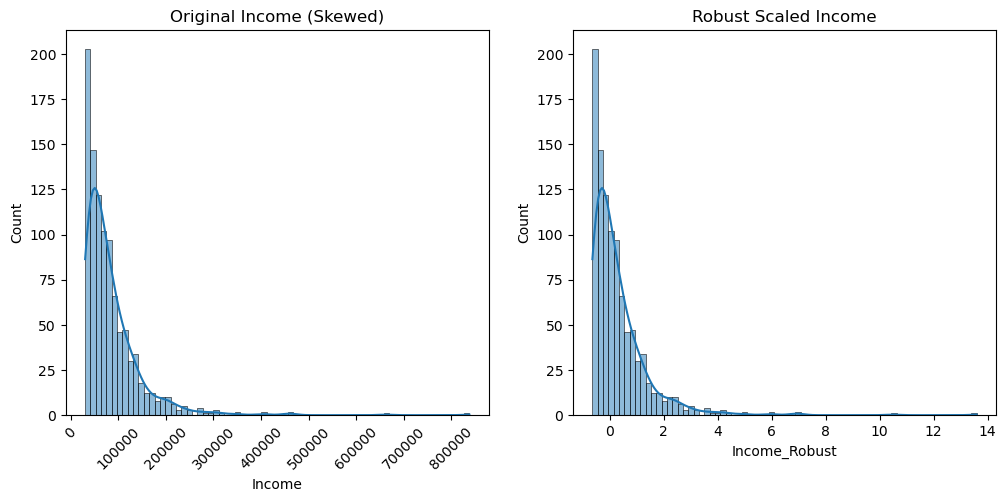

In [7]:
from sklearn.preprocessing import RobustScaler

scaler_robust = RobustScaler()
data['Income_Robust'] = scaler_robust.fit_transform(data[['Income']])

# Log the action
log.log_action(
    category='Scaling',
    action='RobustScaler',
    details='Applied Robust Scaling to Income to handle outliers.',
    columns_affected=['Income']
)

# Compare Distributions Before and After
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data['Income'], kde=True, ax=axes[0]).set_title('Original Income (Skewed)')
axes[0].tick_params(axis='x', rotation=45) # Rotate labels for better visibility

sns.histplot(data['Income_Robust'], kde=True, ax=axes[1]).set_title('Robust Scaled Income')
plt.show()

# Drop original Income
data = data.drop('Income', axis=1)


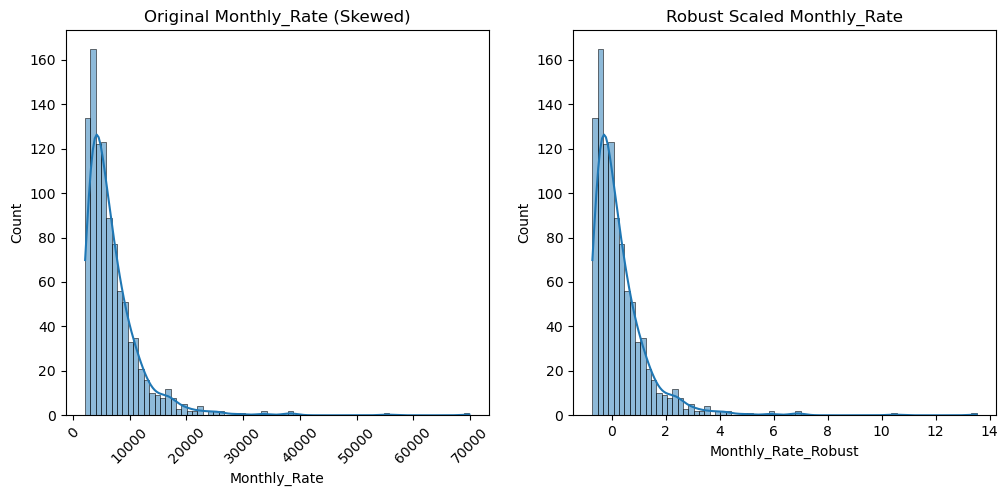

In [8]:
# Scale Monthly_Rate using RobustScaler (Skewed + Outliers)

scaler_robust_monthly = RobustScaler()
data['Monthly_Rate_Robust'] = scaler_robust_monthly.fit_transform(data[['Monthly_Rate']])

# Log the action
log.log_action(
    category='Scaling',
    action='RobustScaler',
    details='Applied Robust Scaling to Monthly_Rate to handle outliers.',
    columns_affected=['Monthly_Rate']
)

# Compare Distributions Before and After
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data['Monthly_Rate'], kde=True, ax=axes[0]).set_title('Original Monthly_Rate (Skewed)')
axes[0].tick_params(axis='x', rotation=45) # Rotate labels for better visibility

sns.histplot(data['Monthly_Rate_Robust'], kde=True, ax=axes[1]).set_title('Robust Scaled Monthly_Rate')
plt.show()

# Drop original Monthly_Rate
data = data.drop('Monthly_Rate', axis=1)


## 4. Binning (Discretization)


### Binning Functions: pd.cut() vs pd.qcut()

**pd.cut()** - Bins data into intervals. 
- **Equal-width bins:** `pd.cut(data, bins=4)` automatically creates 4 equal-width bins
- **Custom bins:** `pd.cut(data, bins=[0, 18, 35, 50, 100])` uses your specified edges (may be unequal width)

**pd.qcut()** - Bins data into equal-sized groups based on quantiles.

**Example:**
```python
# pd.cut() - Equal width bins
data['age_group'] = pd.cut(data['Age'], bins=[0, 18, 35, 50, 100], labels=['Teen', 'Adult', 'Middle', 'Senior'])

# pd.qcut() - Equal size bins (quartiles)
data['income_quartile'] = pd.qcut(data['Income'], q=4, labels=['Q1', 'Q2', 'Q3', 'Q4'])
```


--- Experience Level Distribution ---
Experience_Level
Junior       110
Mid-level    132
Senior       172
Team-lead    172
Manager      414
Name: count, dtype: int64


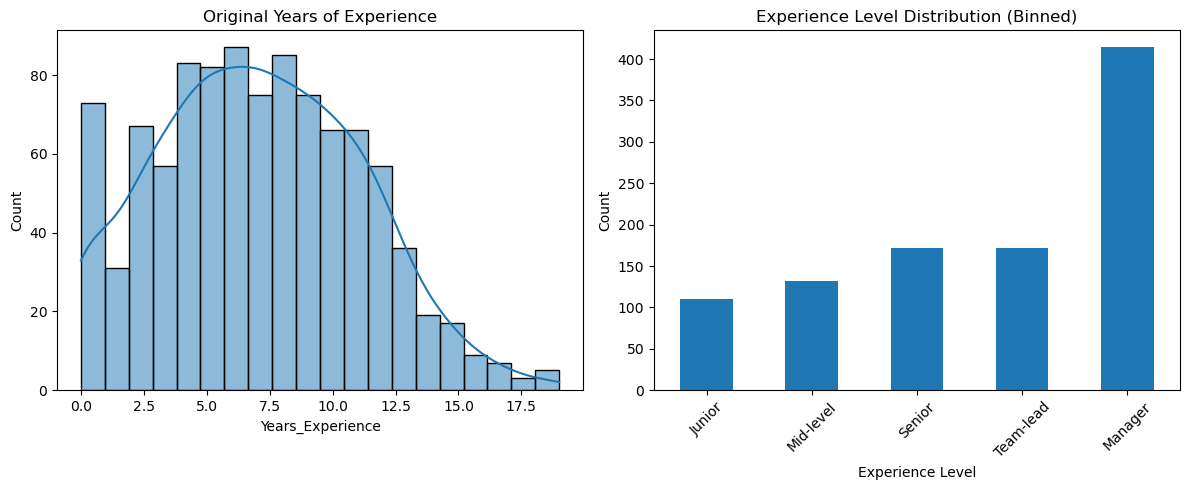

In [9]:
# Discretize Years_Experience into bins (Discretization)
# Define bin boundaries and labels
bins = [0, 2, 4, 6, 8, 50]
labels = ['Junior', 'Mid-level', 'Senior', 'Team-lead', 'Manager']

# Create Experience_Level column using pd.cut
# right=False: Bins look like [0, 2). This means "including 0, up to but not including 2."
# include_lowest=True: Forces the first bin to include that starting value.
data['Experience_Level'] = pd.cut(data['Years_Experience'], bins=bins, labels=labels, right=False, include_lowest=True)

# Log the action
log.log_action(
    category='Discretization',
    action='Binning',
    details='Binned Years_Experience into categories: Junior (0-2), Mid-level (3-5), Senior (6-10), Team-lead (11+).',
    columns_affected=['Years_Experience']
)

# Show distribution of experience levels
print("--- Experience Level Distribution ---")
print(data['Experience_Level'].value_counts().sort_index())

# Visualize the distribution
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(data['Years_Experience'], kde=True, bins=20).set_title("Original Years of Experience")
plt.subplot(1, 2, 2)
data['Experience_Level'].value_counts().sort_index().plot(kind='bar')
plt.title("Experience Level Distribution (Binned)")
plt.xlabel("Experience Level")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 5. Feature Encoding



### Encoding Techniques Summary


<style>
  .custom-table {
    width: 100%;
    border-collapse: collapse;
    font-family: sans-serif;
  }
  .custom-table th {
    background-color:rgb(89, 126, 250); /* Green Header */
    color: black;
    padding: 12px;
    text-align: left;
  }
  .custom-table td {
    border: 1px solid #ddd;
    padding: 10px;
    vertical-align: top;
  }
  .custom-table tr:nth-child(even) {
    background-color:black; /* Striped rows */
  }
  .custom-table tr:hover {
    background-color:rgb(33, 49, 141); /* Hover effect */
  }
  /* .tag {
    font-weight: bold;
    color:rgba(9, 202, 18, 0);
  } */
</style>

<table class="custom-table">
  <thead>
    <tr>
      <th>Technique</th>
      <th>How It Works</th>
      <th>Example</th>
      <th>Pros</th>
      <th>Cons</th>
      <th>When to Use</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td><b>One-Hot Encoding</b></td>
      <td>Creates binary columns (0/1) for each category. Each category becomes a separate column.</td>
      <td><code>Department</code>: Sales, R&D, HR → <code>Dept_Sales</code>, <code>Dept_R&D</code>, <code>Dept_HR</code></td>
      <td>• No ordinal relationship assumed<br> • Works well with linear models</td>
      <td>• Increases dimensionality (curse of dimensionality)<br>• Creates sparse matrix<br>• Can cause multicollinearity if not using drop_first</td>
      <td><b>Nominal</b> categorical features with <b>low cardinality</b> (2-10 categories)</td>
    </tr>
    <tr>
      <td><b>Ordinal/Label Encoding</b></td>
      <td>Maps categories to integers (0, 1, 2, ...) based on order</td>
      <td><code>Education_Level</code>: High School=0, Bachelor=1, Master=2, PhD=3</td>
      <td>• Preserves ordinal relationships<br>• Maintains single column<br>• Simple and fast</td>
      <td>• Assumes equal distance between categories<br>• May mislead algorithms about relationships for nominal data</td>
      <td><b>Ordinal</b> categorical features where order matters (e.g., education levels, ratings)</td>
    </tr>
    <tr>
      <td><b>Frequency Encoding</b></td>
      <td>Replaces categories with their frequency/count in the dataset</td>
      <td><code>ZipCode</code>: 10001 appears 50 times → encoded as 50</td>
      <td>• Maintains single column<br>• Captures category popularity<br>• Works with any cardinality</td>
      <td>• Loses category identity<br>• Same frequency = same encoding<br>• May not capture relationships</td>
      <td>High cardinality features where frequency matters (e.g., zip codes, product IDs)</td>
    </tr>
    <tr>
      <td><b>Target Encoding (Mean Encoding)</b></td>
      <td>Replaces categories with the mean target value for that category</td>
      <td><code>City</code>: Replace with average <code>Purchase_Amount</code> per city</td>
      <td>• Captures target relationship<br>• Maintains single column<br>• Can improve model performance</td>
      <td>• Risk of overfitting<br>• Requires target variable<br>• Needs careful validation (cross-validation)</td>
      <td>High cardinality features when you have target information and want to capture relationships</td>
    </tr>
    <tr>
      <td><b>Binary Encoding</b></td>
      <td>Converts categories to integers, then to binary representation, creating log₂(N) columns</td>
      <td><code>Job_Role</code> (20 categories) → 5 binary columns instead of 20 One-Hot columns</td>
      <td>• Reduces dimensionality vs One-Hot<br>• Good for high cardinality<br>• Preserves some category information</td>
      <td>• Less interpretable</td>
      <td><b>Nominal</b> features with <b>high cardinality</b> (10+ categories)</td>
    </tr>
  </tbody>
</table>

<p align="center">
  <img src="encoding_flow.png" width="50%"/>
</p>

We choose the encoding technique based on the feature's type (Nominal vs. Ordinal) and Cardinality (Number of unique values).

### 5.1 One-Hot Encoding
- **Use Case:** `Department` (**Nominal**, **Low Cardinality**: 3 values).
- **Pros:** No ordinal relationship assumed.
- **Cons:** Increases dimensionality.

In [10]:
# Using pandas get_dummies
dept_encoded = pd.get_dummies(data['Department'], prefix='Dept', drop_first=True)
print(dept_encoded.head())

# Join back to data and drop original
data = pd.concat([data, dept_encoded], axis=1)
data = data.drop('Department', axis=1)

# Log the action
log.log_action(
    category='Encoding',
    action='One-Hot Encoding',
    details='One-Hot encoded Department column.',
    columns_affected=['Department'],
    after_value=f"Created {dept_encoded.shape[1]} new columns"
)


   Dept_R&D  Dept_Sales
0      True       False
1     False        True
2     False        True
3      True       False
4      True       False


### 5.2 Label Encoding (Ordinal Encoding)
- **Use Case:** `Education_Level` (**Ordinal**: High School < Bachelor < Master < PhD).
- **Is it the same as Label Encoding?** Conceptually, yes. We assign an integer to each category. In `sklearn`, `LabelEncoder` is typically for target variables (y), while `OrdinalEncoder` is for features (X). However, both map categories to numbers based on order.
- **Pros:** Preserves order.
- **Cons:** Assumes equal distance between categories.

In [11]:
from sklearn.preprocessing import OrdinalEncoder

# Define order explicitly
edu_order = [['High School', 'Bachelor', 'Master', 'PhD']]
encoder_ord = OrdinalEncoder(categories=edu_order)

data['Education_Encoded'] = encoder_ord.fit_transform(data[['Education_Level']])
print(data[['Education_Level', 'Education_Encoded']].head())

# Log the action
log.log_action(
    category='Encoding',
    action='Ordinal Encoding',
    details='Encoded Education_Level preserving ordinality.',
    columns_affected=['Education_Level']
)

# Drop original
data = data.drop('Education_Level', axis=1)


  Education_Level  Education_Encoded
0     High School                0.0
1     High School                0.0
2        Bachelor                1.0
3        Bachelor                1.0
4     High School                0.0


In [12]:
# Ordinal Encode Experience_Level (preserves hierarchy: Junior < Mid-level < Senior < Team-lead)
from sklearn.preprocessing import OrdinalEncoder

# Define order explicitly to preserve the hierarchy
exp_order = [['Junior', 'Mid-level', 'Senior', 'Team-lead','Manager']]
encoder_exp = OrdinalEncoder(categories=exp_order)

data['Experience_Level_Encoded'] = encoder_exp.fit_transform(data[['Experience_Level']])
print(data[['Experience_Level', 'Experience_Level_Encoded']].head())

# Log the action
log.log_action(
    category='Encoding',
    action='Ordinal Encoding',
    details='Ordinal encoded Experience_Level preserving hierarchy (Junior=0, Mid-level=1, Senior=2, Team-lead=3).',
    columns_affected=['Experience_Level']
)

# Drop original categorical Experience_Level and numeric Years_Experience
data = data.drop('Experience_Level', axis=1)
data = data.drop('Years_Experience', axis=1)


  Experience_Level  Experience_Level_Encoded
0          Manager                       4.0
1        Mid-level                       1.0
2        Mid-level                       1.0
3          Manager                       4.0
4          Manager                       4.0


### 5.3 Binary Encoding
- **Use Case:** `Job_Role` (**Nominal**, **High Cardinality**: 20 values).
- **How it works:** Converts categories to integers, then to binary digits, creating $\log_2(N)$ columns.
- **Why?** One-Hot would create 20 columns. Binary creates only ~5 columns. Best for high cardinality features.

In [13]:
import category_encoders as ce

# Initialize Binary Encoder
encoder_bin = ce.BinaryEncoder(cols=['Job_Role'])

# Fit and Transform
data_bin = encoder_bin.fit_transform(data[['Job_Role']])

print(f"Original Unique Roles: {data['Job_Role'].nunique()}")
print(f"Binary Encoded Columns: {data_bin.shape[1]}")
print(data_bin.head())

# Join back to data and drop original
data = pd.concat([data, data_bin], axis=1)
data = data.drop('Job_Role', axis=1)

# Log the action
log.log_action(
    category='Encoding',
    action='Binary Encoding',
    details='Binary encoded Job_Role (High Cardinality).',
    columns_affected=['Job_Role'],
    after_value=f"Created {data_bin.shape[1]} columns"
)


Original Unique Roles: 20
Binary Encoded Columns: 5
   Job_Role_0  Job_Role_1  Job_Role_2  Job_Role_3  Job_Role_4
0           0           0           0           0           1
1           0           0           0           1           0
2           0           0           0           1           1
3           0           0           1           0           0
4           0           0           1           0           1


## 6. Feature Interactions

Creating new features to capture relationships between existing ones. Sometimes the interaction is more predictive than the individual features.

### 6.1 Arithmetic Addition & Subtraction
Combining features to create meaningful aggregates or differences.

In [14]:
# Example 1: Financial Analysis (Total & Passive Income)
df_fin = pd.DataFrame({
    'salary': [50000, 75000, 60000],
    'bonus': [5000, 10000, 8000],
    'investment_income': [2000, 5000, 1000],
    'rental_income': [12000, 0, 6000]
})

# Interaction A: Total Income
df_fin['total_income'] = df_fin['salary'] + df_fin['bonus'] + df_fin['investment_income'] + df_fin['rental_income']

# Interaction B: Passive Income
df_fin['passive_income'] = df_fin['investment_income'] + df_fin['rental_income']

# Interaction C: Active Income
df_fin['active_income'] = df_fin['salary'] + df_fin['bonus']

# Interaction D: Net Promoter Score (Difference)
# standard business metric used to measure customer loyalty and satisfaction.
# Hypothetical: Promoters % - Detractors %
# Promoters : They are loyal enthusiasts who will keep buying and refer others
# Detractors : They are unhappy customers who can damage your brand through negative word-of-mouth
df_nps = pd.DataFrame({
    'promoters_pct': [0.60, 0.30, 0.80],
    'detractors_pct': [0.10, 0.40, 0.05]
})
df_nps['NPS_Score'] = df_nps['promoters_pct'] - df_nps['detractors_pct']

print("--- Financial Interactions ---")
print(df_fin[['total_income', 'passive_income', 'active_income']])
print("\n--- Difference Interaction (NPS) ---")
print(df_nps)


--- Financial Interactions ---
   total_income  passive_income  active_income
0         69000           14000          55000
1         90000            5000          85000
2         75000            7000          68000

--- Difference Interaction (NPS) ---
   promoters_pct  detractors_pct  NPS_Score
0            0.6            0.10       0.50
1            0.3            0.40      -0.10
2            0.8            0.05       0.75


### 6.2 Arithmetic Multiplication & Division (Ratios)
Ratios normalize values and reveal relationships that raw numbers hide.

In [15]:
# Example 2: Real Estate - Price Efficiency
df_re = pd.DataFrame({
    'price': [500000, 750000, 400000],
    'square_feet': [2000, 2500, 1500],
    'bedrooms': [3, 4, 2],
    'lot_size_sqft': [5000, 6000, 4000]
})

# Interaction A: Price per square foot (Standardized Pricing)
df_re['price_per_sqft'] = df_re['price'] / df_re['square_feet']

# Interaction B: Space Efficiency (Indoor vs Outdoor)
# lot_size_sqft: total area of the land that a property sits on, measured in square feet.
df_re['indoor_outdoor_ratio'] = df_re['square_feet'] / df_re['lot_size_sqft']

# Interaction C: Price per Bedroom (Value for Money)
df_re['price_per_bedroom'] = df_re['price'] / df_re['bedrooms']

print("\n--- Real Estate Ratios ---")
print(df_re[['price_per_sqft', 'indoor_outdoor_ratio', 'price_per_bedroom']])



--- Real Estate Ratios ---
   price_per_sqft  indoor_outdoor_ratio  price_per_bedroom
0      250.000000              0.400000      166666.666667
1      300.000000              0.416667      187500.000000
2      266.666667              0.375000      200000.000000


### 6.3 RFM Analysis (Domain-Specific)
* RFM stands for Recency, Frequency, and Monetary Value.
* It is a behavior-based segmentation technique used to group customers based on their transaction history.

In [16]:
# Simulated E-commerce Data
df_rfm = pd.DataFrame({
    'customer_id': [1, 2, 3],
    'recency_days': [5, 150, 20],  # Days since last purchase
    'frequency': [20, 2, 5],       # Total purchases
    'monetary': [5000, 100, 300]   # Total spend
})

# Define segments based on interactions
def get_segment(row):
    if row['recency_days'] < 30 and row['frequency'] > 10:
        return 'Champion'
    elif row['recency_days'] > 100:
        return 'Churned'
    else:
        return 'Regular'

df_rfm['Segment'] = df_rfm.apply(get_segment, axis=1)
print("\n--- RFM Segments ---")
print(df_rfm)



--- RFM Segments ---
   customer_id  recency_days  frequency  monetary   Segment
0            1             5         20      5000  Champion
1            2           150          2       100   Churned
2            3            20          5       300   Regular


### 6.4 Statistical Aggregations (Group-Based)
Calculate statistics within groups to capture relative position and patterns.

In [17]:
# E-commerce: Product performance by category
df_stats = pd.DataFrame({
    'product': ['Laptop', 'Headphones', 'Monitor', 'T-Shirt', 'Jeans', 'Sneakers', 'Blender', 'Toaster'],
    'category': ['Electronics', 'Electronics', 'Electronics', 'Clothing', 'Clothing', 'Clothing', 'Kitchen', 'Kitchen'],
    'price': [1200, 150, 300, 25, 60, 80, 50, 30],
    'units_sold': [120, 450, 200, 500, 300, 250, 150, 180]
})

# Interaction A: Relative Price (Is this product expensive for its category?)
# 1. Calculate Mean Price per Category
# .transform('mean') takes those means and broadcasts them back to every original row.
category_mean_price = df_stats.groupby('category')['price'].transform('mean')

# High ratio = Premium product within its category
df_stats['price_vs_category_mean'] = df_stats['price'] / category_mean_price

# Interaction B: Sales Efficiency (Sales relative to the category best-seller)
# 2. Calculate Max Sales per Category
category_max_sales = df_stats.groupby('category')['units_sold'].transform('max')

# Ratio close to 1 = Market leader in that category
df_stats['sales_efficiency'] = df_stats['units_sold'] / category_max_sales

print("\n--- Statistical Aggregation ---")
print(df_stats[['category', 'product', 'price', 'price_vs_category_mean', 'sales_efficiency']])



--- Statistical Aggregation ---
      category     product  price  price_vs_category_mean  sales_efficiency
0  Electronics      Laptop   1200                2.181818          0.266667
1  Electronics  Headphones    150                0.272727          1.000000
2  Electronics     Monitor    300                0.545455          0.444444
3     Clothing     T-Shirt     25                0.454545          1.000000
4     Clothing       Jeans     60                1.090909          0.600000
5     Clothing    Sneakers     80                1.454545          0.500000
6      Kitchen     Blender     50                1.250000          0.833333
7      Kitchen     Toaster     30                0.750000          1.000000


### 6.5 Temporal Aggregations
Aggregating over time windows creates powerful features.
$$\text{Momentum} = \frac{\text{Spend (Current Month)}}{\text{Average Spend (Last 2 Months)}}$$

In [18]:
# Customer purchase momentum
df_temp = pd.DataFrame({
    'customer_id': [1, 2],
    'spend_last_30d': [500, 50],
    'spend_last_60d': [600, 500] 
})

# Momentum: Recent spend vs historical baseline
# If ratio > 1, spending is accelerating. If < 1, slowing down (churn risk).
df_temp['spend_momentum'] = df_temp['spend_last_30d'] / (df_temp['spend_last_60d'] / 2)

print("\n--- Temporal Aggregation ---")
print(df_temp)



--- Temporal Aggregation ---
   customer_id  spend_last_30d  spend_last_60d  spend_momentum
0            1             500             600        1.666667
1            2              50             500        0.200000


### 6.6 Practical Example on Employee Data
Applying a ratio interaction to our main dataset.

In [19]:
# Create Interaction: Performance Efficiency
# We add 1 to encoded experience level to avoid division by zero (using binned and encoded version)
data['Performance_Efficiency'] = data['Performance_Scaled'] / (data['Experience_Level_Encoded'] + 1)

# Log the action
log.log_action(
    category='Feature Interaction',
    action='Ratio Creation',
    details='Created Performance_Efficiency = Performance_Scaled / (Experience_Level_Encoded + 1) using binned experience levels.',
    columns_affected=['Performance_Efficiency']
)

print("--- New Feature: Performance_Efficiency ---")
print(data[['Experience_Level_Encoded', 'Performance_Scaled', 'Performance_Efficiency']].head())


--- New Feature: Performance_Efficiency ---
   Experience_Level_Encoded  Performance_Scaled  Performance_Efficiency
0                       4.0               0.225                  0.0450
1                       1.0               0.025                  0.0125
2                       1.0               0.100                  0.0500
3                       4.0               0.350                  0.0700
4                       4.0               0.800                  0.1600


## 7. Feature Selection



Identifying redundant features to improve model performance and reduce overfitting.

### 7.1 Filter Methods
- **Variance Threshold:** Remove constant features.
- **Correlation Matrix:** Remove highly correlated features (Multicollinearity).

In [20]:
# 1. Variance Threshold
from sklearn.feature_selection import VarianceThreshold

# Create dummy constant feature
data['Constant_Feature'] = 1

selector = VarianceThreshold(threshold=0) # Remove features with 0 variance
selector.fit(data) # Check all columns
# Note: VarianceThreshold usually works on numerical data, but we've encoded everything now.
print("Features kept:", data.columns[selector.get_support()].tolist())

# Drop the constant feature for next steps
data = data.drop('Constant_Feature', axis=1)


Features kept: ['Attrition', 'Age_Scaled', 'Performance_Scaled', 'Income_Robust', 'Monthly_Rate_Robust', 'Dept_R&D', 'Dept_Sales', 'Education_Encoded', 'Experience_Level_Encoded', 'Job_Role_0', 'Job_Role_1', 'Job_Role_2', 'Job_Role_3', 'Job_Role_4', 'Performance_Efficiency']


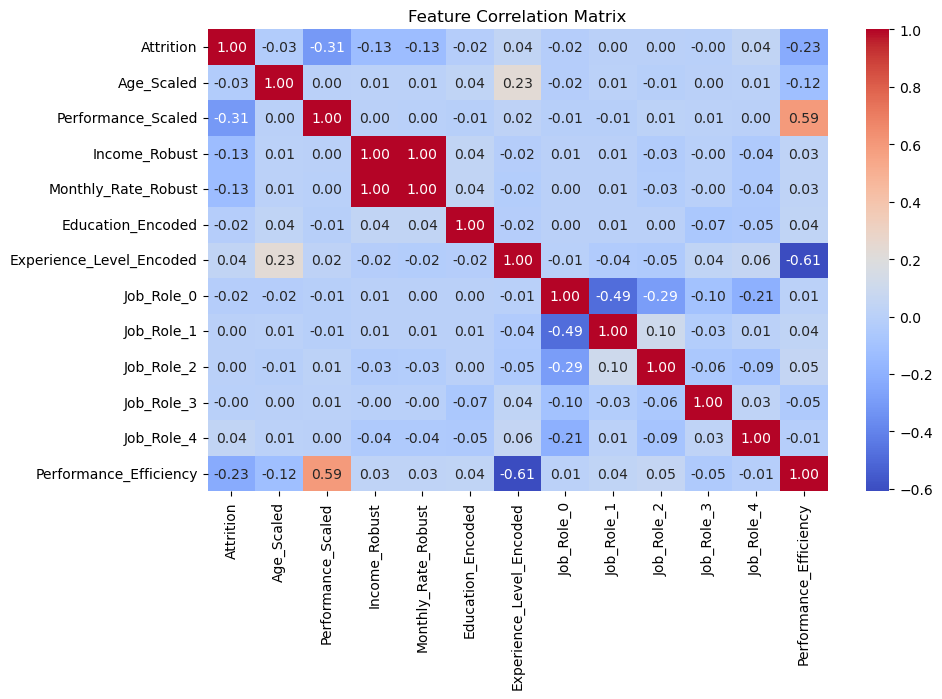

In [21]:
# 2. Correlation Matrix
# Select only numerical columns for correlation
numerical_cols = data.select_dtypes(include=[np.number]).columns
corr_matrix = data[numerical_cols].corr()

plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm')
plt.title("Feature Correlation Matrix")
plt.show()

#### Note on Correlation
- **Look for off-diagonal correlations > 0.8 (or < -0.8).**
- High multicollinearity affects linear models (Linear Reg, Logistic Reg, SVM).
- Tree-based models (Random Forest, XGBoost) are generally robust to multicollinearity.
- **Action:** If `Feature A` and `Feature B` are highly correlated, drop one of them.


In [22]:
# Automatically remove features with correlation > 0.8
# Get absolute correlation matrix
corr_abs = corr_matrix.abs()

# Select upper triangle of correlation matrix
upper = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))

# Find features with correlation greater than 0.8
to_drop = [column for column in upper.columns if any(upper[column] > 0.8)]

print(f"Features to drop (correlation > 0.8): {to_drop}")

# Drop features
data = data.drop(to_drop, axis=1)
print(f"Remaining features: {data.columns.tolist()}")

# Log the action
log.log_action(
    category='Feature Selection',
    action='Correlation Filtering',
    details=f'Removed features with correlation > 0.8: {to_drop}',
    columns_affected=to_drop,
    rows_affected=0
)


Features to drop (correlation > 0.8): ['Monthly_Rate_Robust']
Remaining features: ['Attrition', 'Age_Scaled', 'Performance_Scaled', 'Income_Robust', 'Dept_R&D', 'Dept_Sales', 'Education_Encoded', 'Experience_Level_Encoded', 'Job_Role_0', 'Job_Role_1', 'Job_Role_2', 'Job_Role_3', 'Job_Role_4', 'Performance_Efficiency']


### 7.2 Wrapper Methods
Wrapper methods evaluate feature subsets by training models and measuring performance.

#### Forward Selection vs. Backward Elimination
We will manually demonstrate the iterative process to show how performance changes as we add/remove features.

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
import warnings
from sklearn.exceptions import ConvergenceWarning

# Suppress convergence warnings for cleaner output
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# Prepare data
X = data.drop('Attrition', axis=1) # Features
y = data['Attrition']              # Target
X = X.fillna(X.mean())

# --- Manual Forward Selection Demo ---
print("--- Manual Forward Selection Process ---")
remaining_features = list(X.columns)
forward_selected_features = []
current_score = 0.0

# Select top 5 features manually
for i in range(5):
    best_score = 0.0
    best_feature = None
    
    print(f"\nIteration {i+1}: Testing {len(remaining_features)} features...")
    
    for feature in remaining_features:
        # Train model with current selected + new feature
        features_to_test = forward_selected_features + [feature]
        model = LogisticRegression(max_iter=5000, solver='liblinear') # Increased max_iter
        score = cross_val_score(model, X[features_to_test], y, cv=3).mean()
        
        if score > best_score:
            best_score = score
            best_feature = feature
            
    if best_feature:
        forward_selected_features.append(best_feature)
        remaining_features.remove(best_feature)
        print(f"  -> Added '{best_feature}' (New Accuracy: {best_score:.4f})")
        if best_score - current_score < 0.001:
            print("  -> Improvement minimal, stopping early (simulated).")
        current_score = best_score

print(f"\nFinal Selected Features (Manual Forward): {forward_selected_features}")



--- Manual Forward Selection Process ---

Iteration 1: Testing 13 features...


  -> Added 'Performance_Scaled' (New Accuracy: 0.6760)

Iteration 2: Testing 12 features...
  -> Added 'Income_Robust' (New Accuracy: 0.7090)

Iteration 3: Testing 11 features...
  -> Added 'Performance_Efficiency' (New Accuracy: 0.7130)

Iteration 4: Testing 10 features...
  -> Added 'Job_Role_1' (New Accuracy: 0.7100)
  -> Improvement minimal, stopping early (simulated).

Iteration 5: Testing 9 features...
  -> Added 'Experience_Level_Encoded' (New Accuracy: 0.7080)
  -> Improvement minimal, stopping early (simulated).

Final Selected Features (Manual Forward): ['Performance_Scaled', 'Income_Robust', 'Performance_Efficiency', 'Job_Role_1', 'Experience_Level_Encoded']


In [24]:


# --- Manual Backward Elimination Demo ---
print("\n--- Manual Backward Elimination Process ---")
backward_current_features = list(X.columns)
# Initial score with all features
model = LogisticRegression(max_iter=5000, solver='liblinear')
initial_score = cross_val_score(model, X[backward_current_features], y, cv=3).mean()
print(f"Initial Accuracy (All Features): {initial_score:.4f}")

# Remove 5 features
for i in range(5):
    best_new_score = 0.0
    worst_feature = None
    
    print(f"\nIteration {i+1}: Testing removal of 1 feature from {len(backward_current_features)}...")
    
    for feature in backward_current_features:
        # Train model WITHOUT this feature
        features_to_keep = [f for f in backward_current_features if f != feature]
        model = LogisticRegression(max_iter=5000, solver='liblinear')
        score = cross_val_score(model, X[features_to_keep], y, cv=3).mean()
        
        # We want the highest score after removal (meaning the feature was least important/harmful)
        if score > best_new_score:
            best_new_score = score
            worst_feature = feature
            
    if worst_feature:
        backward_current_features.remove(worst_feature)
        print(f"  -> Removed '{worst_feature}' (New Accuracy: {best_new_score:.4f})")
        
    # Also remove from data for next steps if desired (here we just simulate)

print(f"\nFinal Selected Features (Manual Backward): {backward_current_features}")



--- Manual Backward Elimination Process ---
Initial Accuracy (All Features): 0.6880

Iteration 1: Testing removal of 1 feature from 13...
  -> Removed 'Job_Role_0' (New Accuracy: 0.7000)

Iteration 2: Testing removal of 1 feature from 12...
  -> Removed 'Job_Role_2' (New Accuracy: 0.7040)

Iteration 3: Testing removal of 1 feature from 11...
  -> Removed 'Performance_Efficiency' (New Accuracy: 0.7040)

Iteration 4: Testing removal of 1 feature from 10...
  -> Removed 'Education_Encoded' (New Accuracy: 0.7080)

Iteration 5: Testing removal of 1 feature from 9...
  -> Removed 'Age_Scaled' (New Accuracy: 0.7100)

Final Selected Features (Manual Backward): ['Performance_Scaled', 'Income_Robust', 'Dept_R&D', 'Dept_Sales', 'Experience_Level_Encoded', 'Job_Role_1', 'Job_Role_3', 'Job_Role_4']


In [25]:
print(f"\nFinal Selected Features (Manual Forward): {forward_selected_features}")
print(f"\nFinal Selected Features (Manual Backward): {backward_current_features}")


Final Selected Features (Manual Forward): ['Performance_Scaled', 'Income_Robust', 'Performance_Efficiency', 'Job_Role_1', 'Experience_Level_Encoded']

Final Selected Features (Manual Backward): ['Performance_Scaled', 'Income_Robust', 'Dept_R&D', 'Dept_Sales', 'Experience_Level_Encoded', 'Job_Role_1', 'Job_Role_3', 'Job_Role_4']


#### Analysis of Results
You might notice something interesting in the results above:

1.  **Accuracy Parity and Different Feature Sets:** Forward Selection and Backward Elimination might select different features. Wrapper methods are "**greedy**" they make the best local decision at each step but don't guarantee finding the global optimal combination.
3.  **Partial Encoded Features:** You might see features like `Job_Role_1` selected. This is a single column from our Binary Encoding.
    *   **Why?** The model treats each encoded column as an independent feature.
    *   **Meaning:** If `Job_Role_1` is selected, it means that specific "bit" or split of categories has strong predictive power (e.g., it might separate "Sales" from "HR").

In [26]:
from sklearn.feature_selection import SequentialFeatureSelector

# --- Using SequentialFeatureSelector (Automated) ---
print("\n--- Automated SequentialFeatureSelector ---")

# 1. Forward Selection
sfs_forward = SequentialFeatureSelector(
    LogisticRegression(max_iter=5000, solver='liblinear'), 
    n_features_to_select=5, 
    direction='forward'
)
sfs_forward.fit(X, y)
print("Top 5 Features Selected (Forward SFS):", X.columns[sfs_forward.get_support()].tolist())

# 2. Backward Elimination
sfs_backward = SequentialFeatureSelector(
    LogisticRegression(max_iter=5000, solver='liblinear'), 
    n_features_to_select=5, 
    direction='backward'
)
sfs_backward.fit(X, y)
print("Top 5 Features Selected (Backward SFS):", X.columns[sfs_backward.get_support()].tolist())



--- Automated SequentialFeatureSelector ---
Top 5 Features Selected (Forward SFS): ['Performance_Scaled', 'Income_Robust', 'Experience_Level_Encoded', 'Job_Role_4', 'Performance_Efficiency']
Top 5 Features Selected (Backward SFS): ['Performance_Scaled', 'Income_Robust', 'Dept_R&D', 'Dept_Sales', 'Experience_Level_Encoded']


#### Recursive Feature Elimination (RFE) & RFECV
A powerful wrapper method that works by recursively removing the weakest features. <br>
* **Start with all features** : train a chosen model (e.g., logistic regression, SVM) on the dataset.
* **Rank features by importance** : use importance scores to measure contribution.
* **Eliminate weakest feature(s)** : drop the least important one(s) from the dataset.
* **Retrain and repeat** : fit the model again on the reduced set, re‑rank, and remove the next weakest.


**RFE vs. RFECV:**
*   **RFE (Recursive Feature Elimination):** You specify the number of features (`n_features_to_select`). It gives you the best subset of that size.
*   **RFECV (RFE with Cross-Validation):** Automatically finds the optimal number of features for you.

**Advantages:**
1. **Faster than forward/backward:** Uses feature importance from the model itself, not brute force trial-and-error.
2. **Model Agnostic:** Works with any model that provides feature importance (coeffs or feature_importances_).
3. **Optimal Number (RFECV):** Automatically finds the best number of features.

In [27]:
from sklearn.feature_selection import RFE, RFECV
from sklearn.linear_model import LogisticRegression

# Initialize model
model = LogisticRegression(max_iter=5000, solver='liblinear')

# --- 1. Standard RFE (Manual Count) ---
# You choose the number of features (e.g., 3)
rfe = RFE(model, n_features_to_select=5)
rfe.fit(X, y)

print("--- RFE (Select 5) Results ---")
print("Top 5 Features:", X.columns[rfe.support_].tolist())

# --- 2. RFECV (Automatic Count) ---
# Automatically finds optimal number of features using Cross-Validation
rfecv = RFECV(estimator=model, step=1, cv=3, scoring='accuracy')
rfecv.fit(X, y)

print("\n--- RFECV (Automatic) Results ---")
print("Optimal number of features:", rfecv.n_features_)
print("Best Features:", X.columns[rfecv.support_].tolist())

# Log the feature selection results
best_features = X.columns[rfecv.support_].tolist()
log.log_action(
    category='Feature Selection',
    action='RFECV',
    details=f'RFECV selected optimal number of features: {rfecv.n_features_}. Best features obtained: {best_features}',
    columns_affected=best_features,
    rows_affected=0
)


--- RFE (Select 5) Results ---
Top 5 Features: ['Performance_Scaled', 'Income_Robust', 'Dept_R&D', 'Dept_Sales', 'Performance_Efficiency']

--- RFECV (Automatic) Results ---
Optimal number of features: 7
Best Features: ['Performance_Scaled', 'Income_Robust', 'Dept_R&D', 'Dept_Sales', 'Job_Role_0', 'Job_Role_4', 'Performance_Efficiency']


## 8. Documentation

Always maintain a transformation log.

In [28]:
# Display the full log as a DataFrame
print("--- Transformation Log ---")
display(log.to_dataframe())


--- Transformation Log ---


,timestamp,category,action,details,rows_affected,columns_affected,before_value,after_value
0,2026-03-25 19:38:51,Scaling,StandardScaler,Applied Z-Score standardization to Age (Normal...,NaN,[Age],None,None
1,2026-03-25 19:38:52,Scaling,MinMaxScaler,"Scaled Performance_Score to [0, 1] range.",NaN,[Performance_Score],None,None
2,2026-03-25 19:38:52,Scaling,RobustScaler,Applied Robust Scaling to Income to handle out...,NaN,[Income],None,None
3,2026-03-25 19:38:53,Scaling,RobustScaler,Applied Robust Scaling to Monthly_Rate to hand...,NaN,[Monthly_Rate],None,None
4,2026-03-25 19:38:53,Discretization,Binning,Binned Years_Experience into categories: Junio...,NaN,[Years_Experience],None,None
5,2026-03-25 19:38:54,Encoding,One-Hot Encoding,One-Hot encoded Department column.,NaN,[Department],None,Created 2 new columns
6,2026-03-25 19:38:54,Encoding,Ordinal Encoding,Encoded Education_Level preserving ordinality.,NaN,[Education_Level],None,None
7,2026-03-25 19:38:54,Encoding,Ordinal Encoding,Ordinal encoded Experience_Level preserving hi...,NaN,[Experience_Level],None,None
8,2026-03-25 19:38:54,Encoding,Binary Encoding,Binary encoded Job_Role (High Cardinality).,NaN,[Job_Role],None,Created 5 columns
9,2026-03-25 19:38:54,Feature Interaction,Ratio Creation,Created Performance_Efficiency = Performance_S...,NaN,[Performance_Efficiency],None,None
